In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display, clear_output
import time

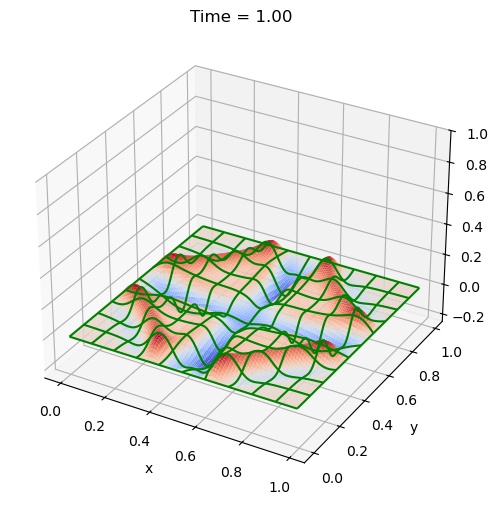

In [2]:
L  = 1
mu = 1
t = 0
T =1
dx = 0.01
dt = 0.707*dx/np.sqrt(T/mu)  #we can't just pick any values for dx and dt. If the speed of 
#your wave is such that it moves the distance dx in less time than dt, it blows up.
R = dt**2*T/(dx**2*mu)


# Generate spatial points
xt = 0
x = []

while xt < L:
    x = x + [xt]
    xt = xt + dx

y = x.copy() 
xx,yy = np.meshgrid(x,y) 

#print(x)

# Initialize three lists with zeros
fnew = []  # k+1 (next time step)
fnow = []  # k   (current time step)
fold = []  # k-1 (previous time step)

for i in range(len(x)):
    fnew = np.zeros((len(x),len(y)))  
    fnow = np.zeros((len(x),len(y)))  
    fold = np.zeros((len(x),len(y))) 

#two copies of the initial string shape, so the simulation has both the current and previous values it needs to begin calculating motion.

xc = 0.5 
w = 0.05 

fnow[:,:] = np.exp(-(xx-xc)**2/(w**2))*np.exp(-(yy-xc)**2/(w**2)) 

fold = fnow.copy()

plt.figure(figsize=(5, 2))
plt.imshow(fnow,origin='lower',extent=[0,L,0,L])
plt.xlabel('x')
plt.ylabel('y') 
plt.show()

#first time step
fnew[1:-1,1:-1] = fnow[1:-1,1:-1] + 0.5*R*(fnow[:-2,1:-1]+fnow[2:,1:-1]-2*fnow[1:-1,1:-1])\
                                    + 0.5*R*(fnow[1:-1,:-2]+fnow[1:-1,2:]-2*fnow[1:-1,1:-1])

fold = fnow.copy() 
fnow = fnew.copy() 

while t < 1:
    fdata = []

    for i in range(1, len(x)-1):              #runs from 1 to 99 excludes 0 and 100
        for j in range(1, len(y)-1): 

            fnew[i,j] = R * (fnow[i+1,j] + fnow[i-1,j] + fnow[i,j+1] + fnow[i,j-1] - 4*fnow[i,j]) - fold[i,j] + 2*fnow[i,j] 

       # Free left endpoint  

    #zero boundary values
    fnew[0,:] = 0
    fnew[-1,:] = 0
    fnew[:,0] = 0
    fnew[:,-1] = 0

    fold = fnow.copy()
    fnow = fnew.copy() 



         #  Advance to the next shape.

    for i in range(len(x)):
        for j in range(len(y)): 

            fdata = fdata + [[x[i], y[j], fnew[i,j]]] 


    t = t + dt

    # Update graph
    clear_output(wait=True)
    plt.figure(figsize=(10,6))
    ax = plt.axes(projection='3d') 
    ax.plot_surface(xx,yy, fnew, rstride=1, cstride=1, cmap='coolwarm') 
    ax.plot_wireframe(xx, yy, fnew, rstride=10, cstride=10, color='green') 

    plt.xlabel('x')
    plt.ylabel('y') 
    plt.title(f'Time = {t:.2f}')

    ax.set_zlim(-.25,1) 

    display(plt.gcf())
    plt.close()

    time.sleep(0.01)